In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from brian2 import *


INFO       Cache size for target 'cython': 2418 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


In [30]:
start_scope()

SEED = 2
seed(SEED)
rng = np.random.default_rng(SEED)


DT = 0.02*ms
REC_DT = 0.5*ms
SIM_TIME = 30*second
DISCARD = 1.0*second

defaultclock.dt = DT

NE = 400
NI = 100

CM = 200*pF

G_NA = 24*uS
G_K  = 7.2*uS
G_L  = 60*nS

E_NA = 50*mV
E_K  = -77*mV
E_L  = -54.4*mV

E_AMPA = 0*mV
E_GABA = -80*mV

TAU_AMPA_RISE  = 0.5*ms
TAU_AMPA_DECAY = 2.0*ms

TAU_GABA_RISE  = 0.5*ms
TAU_GABA_DECAY = 16.0*ms

def gate_jump_norm(tau_rise, tau_decay):
    tr = float(tau_rise/ms)
    td = float(tau_decay/ms)

    t_peak = tr*td/(td-tr) * np.log(td/tr)

    peak = td/(td-tr) * (
        np.exp(-t_peak/td) - np.exp(-t_peak/tr)
    )

    return 1.0/peak

AMPA_NORM = gate_jump_norm(TAU_AMPA_RISE, TAU_AMPA_DECAY)
GABA_NORM = gate_jump_norm(TAU_GABA_RISE, TAU_GABA_DECAY)

print(f'AMPA gate normalization = {AMPA_NORM:.3f}')
print(f'GABA gate normalization = {GABA_NORM:.3f}')

# External AMPA
g_AMPA_ext_E = 2.08*nS
g_AMPA_ext_I = 1.62*nS

# Recurrent AMPA
g_AMPA_rec_E = 0.104*nS * 800/NE
g_AMPA_rec_I = 0.081*nS * 800/NE

# Recurrent GABA_A
g_GABA_E = 1.25*nS * 200/NI
g_GABA_I = 0.973*nS * 200/NI


w_EE = 5.0
w_EI = 9.0
w_IE = 5.0
w_II = 1.5

# Sparse random connectivity
P_EE = 0.15
P_EI = 0.15
P_IE = 0.15
P_II = 0.15

# Delays
DELAY_E_MIN = 1.0*ms
DELAY_E_MAX = 3.0*ms

DELAY_I_MIN = 2.0*ms
DELAY_I_MAX = 5.0*ms


N_EXT_E = 300
N_EXT_I = 300

RATE_EXT_E = 5*Hz#8*Hz
RATE_EXT_I = 6*Hz#8*Hz

w_EXT_E = 0.625
w_EXT_I = 0.68

I_TONIC_E = 0.40*nA
I_TONIC_I = 0.40*nA

eqs_E = r'''
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + I_AMPA_ext
    + I_AMPA_rec
    + I_GABA_rec
    + I_tonic
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dx_AMPA_ext/dt = -x_AMPA_ext/TAU_AMPA_RISE : 1
ds_AMPA_ext/dt = -s_AMPA_ext/TAU_AMPA_DECAY + x_AMPA_ext/TAU_AMPA_RISE : 1

dx_AMPA_rec/dt = -x_AMPA_rec/TAU_AMPA_RISE : 1
ds_AMPA_rec/dt = -s_AMPA_rec/TAU_AMPA_DECAY + x_AMPA_rec/TAU_AMPA_RISE : 1

dx_GABA_rec/dt = -x_GABA_rec/TAU_GABA_RISE : 1
ds_GABA_rec/dt = -s_GABA_rec/TAU_GABA_DECAY + x_GABA_rec/TAU_GABA_RISE : 1

I_AMPA_ext = g_AMPA_ext_E * s_AMPA_ext * (E_AMPA-v) : amp
I_AMPA_rec = g_AMPA_rec_E * s_AMPA_rec * (E_AMPA-v) : amp
I_GABA_rec = g_GABA_E * s_GABA_rec * (E_GABA-v) : amp

I_tonic : amp
'''

eqs_I = r'''
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + I_AMPA_ext
    + I_AMPA_rec
    + I_GABA_rec
    + I_tonic
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dx_AMPA_ext/dt = -x_AMPA_ext/TAU_AMPA_RISE : 1
ds_AMPA_ext/dt = -s_AMPA_ext/TAU_AMPA_DECAY + x_AMPA_ext/TAU_AMPA_RISE : 1

dx_AMPA_rec/dt = -x_AMPA_rec/TAU_AMPA_RISE : 1
ds_AMPA_rec/dt = -s_AMPA_rec/TAU_AMPA_DECAY + x_AMPA_rec/TAU_AMPA_RISE : 1

dx_GABA_rec/dt = -x_GABA_rec/TAU_GABA_RISE : 1
ds_GABA_rec/dt = -s_GABA_rec/TAU_GABA_DECAY + x_GABA_rec/TAU_GABA_RISE : 1

I_AMPA_ext = g_AMPA_ext_I * s_AMPA_ext * (E_AMPA-v) : amp
I_AMPA_rec = g_AMPA_rec_I * s_AMPA_rec * (E_AMPA-v) : amp
I_GABA_rec = g_GABA_I * s_GABA_rec * (E_GABA-v) : amp

I_tonic : amp
'''

namespace_E = {
    'CM': CM,
    'G_NA': G_NA,
    'G_K': G_K,
    'G_L': G_L,
    'E_NA': E_NA,
    'E_K': E_K,
    'E_L': E_L,
    'E_AMPA': E_AMPA,
    'E_GABA': E_GABA,
    'TAU_AMPA_RISE': TAU_AMPA_RISE,
    'TAU_AMPA_DECAY': TAU_AMPA_DECAY,
    'TAU_GABA_RISE': TAU_GABA_RISE,
    'TAU_GABA_DECAY': TAU_GABA_DECAY,
    'g_AMPA_ext_E': g_AMPA_ext_E,
    'g_AMPA_rec_E': g_AMPA_rec_E,
    'g_GABA_E': g_GABA_E,
}

namespace_I = {
    'CM': CM,
    'G_NA': G_NA,
    'G_K': G_K,
    'G_L': G_L,
    'E_NA': E_NA,
    'E_K': E_K,
    'E_L': E_L,
    'E_AMPA': E_AMPA,
    'E_GABA': E_GABA,
    'TAU_AMPA_RISE': TAU_AMPA_RISE,
    'TAU_AMPA_DECAY': TAU_AMPA_DECAY,
    'TAU_GABA_RISE': TAU_GABA_RISE,
    'TAU_GABA_DECAY': TAU_GABA_DECAY,
    'g_AMPA_ext_I': g_AMPA_ext_I,
    'g_AMPA_rec_I': g_AMPA_rec_I,
    'g_GABA_I': g_GABA_I,
}

# ------------------------------------------------------------
# Neuron populations
# ------------------------------------------------------------
E = NeuronGroup(
    NE,
    eqs_E,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace_E,
    name='E'
)

I = NeuronGroup(
    NI,
    eqs_I,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace_I,
    name='I'
)

for G in (E, I):
    G.v = -65*mV
    G.m = 0.0529
    G.h = 0.596
    G.n = 0.318

    G.x_AMPA_ext = 0
    G.s_AMPA_ext = 0
    G.x_AMPA_rec = 0
    G.s_AMPA_rec = 0
    G.x_GABA_rec = 0
    G.s_GABA_rec = 0

E.I_tonic = np.clip(
    rng.normal(float(I_TONIC_E/nA), 0.05, NE),
    0.05, None
)*nA

I.I_tonic = np.clip(
    rng.normal(float(I_TONIC_I/nA), 0.04, NI),
    0.05, None
)*nA

# ------------------------------------------------------------
# Recurrent synapses
# ------------------------------------------------------------

S_EE = Synapses(
    E, E,
    model='w : 1',
    on_pre='x_AMPA_rec_post += AMPA_NORM*w',
    namespace={'AMPA_NORM': AMPA_NORM},
    name='S_EE'
)
S_EE.connect(condition='i != j', p=P_EE)
S_EE.w = w_EE
S_EE.delay = '1*ms + rand()*2*ms'

S_EI = Synapses(
    E, I,
    model='w : 1',
    on_pre='x_AMPA_rec_post += AMPA_NORM*w',
    namespace={'AMPA_NORM': AMPA_NORM},
    name='S_EI'
)
S_EI.connect(p=P_EI)
S_EI.w = w_EI
S_EI.delay = '1*ms + rand()*2*ms'

S_IE = Synapses(
    I, E,
    model='w : 1',
    on_pre='x_GABA_rec_post += GABA_NORM*w',
    namespace={'GABA_NORM': GABA_NORM},
    name='S_IE'
)
S_IE.connect(p=P_IE)
S_IE.w = w_IE
S_IE.delay = '3*ms + rand()*1*ms' 

S_II = Synapses(
    I, I,
    model='w : 1',
    on_pre='x_GABA_rec_post += GABA_NORM*w',
    namespace={'GABA_NORM': GABA_NORM},
    name='S_II'
)
S_II.connect(condition='i != j', p=P_II)
S_II.w = w_II
S_II.delay = '3*ms + rand()*1*ms' 

# ------------------------------------------------------------
# External AMPA
# ------------------------------------------------------------
P_EXT_E = PoissonInput(
    E,
    'x_AMPA_ext',
    N=N_EXT_E,
    rate=RATE_EXT_E,
    weight=AMPA_NORM*w_EXT_E
)

P_EXT_I = PoissonInput(
    I,
    'x_AMPA_ext',
    N=N_EXT_I,
    rate=RATE_EXT_I,
    weight=AMPA_NORM*w_EXT_I
)

# # shared component of the external drive
# OU = NeuronGroup(1, '''drate/dt = (600*Hz - rate)/(100*ms) + sigma*sqrt(2/(100*ms))*xi : Hz''',
#                  namespace={'sigma': 200*Hz}, method='euler', name='OU')
# OU.rate = 600*Hz
# PG_SHARED = PoissonGroup(1, rates='clip(OU_rate(t), 0*Hz, 5000*Hz)')
# #PG_SHARED = PoissonGroup(1, 600*Hz, name='PG_SHARED')
# S_SH_E = Synapses(PG_SHARED, E, on_pre='x_AMPA_ext_post += AMPA_NORM*w_EXT_E',
#                   namespace={'AMPA_NORM': AMPA_NORM, 'w_EXT_E': w_EXT_E}, name='S_SH_E')
# S_SH_I = Synapses(PG_SHARED, I, on_pre='x_AMPA_ext_post += AMPA_NORM*w_EXT_I',
#                   namespace={'AMPA_NORM': AMPA_NORM, 'w_EXT_I': w_EXT_I}, name='S_SH_I')
# S_SH_E.connect(p=1.0)
# S_SH_I.connect(p=1.0)
# ------------------------------------------------------------
# Monitors
# ------------------------------------------------------------
SP_E = SpikeMonitor(E, name='SP_E')
SP_I = SpikeMonitor(I, name='SP_I')

RATE_E = PopulationRateMonitor(E, name='RATE_E')
RATE_I = PopulationRateMonitor(I, name='RATE_I')

CHOSEN_E = 200

M_CELL = StateMonitor(
    E,
    [
        'v',
        's_AMPA_ext',
        's_AMPA_rec',
        's_GABA_rec',
        'I_AMPA_ext',
        'I_AMPA_rec',
        'I_GABA_rec'
    ],
    record=[CHOSEN_E],
    dt=REC_DT,
    name='M_CELL'
)

# Record population synaptic currents directly in compiled Brian2 code.
# LFP summation happens after the simulation.
M_LFP = StateMonitor(
    E,
    ['I_AMPA_ext', 'I_AMPA_rec', 'I_GABA_rec'],
    record= np.arange(0, NE, 4), #True,
    dt=REC_DT,
    name='M_LFP'
)

net = Network(
    E, I,
    S_EE, S_EI, S_IE, S_II,
    P_EXT_E, P_EXT_I,
    SP_E, SP_I,
    RATE_E, RATE_I,
    M_CELL, M_LFP
)

# ============================================================
# Analysis helpers
# ============================================================

def compute_lfp_proxies():
    t = np.asarray(M_LFP.t/second)

    I_ext = np.asarray(M_LFP.I_AMPA_ext/nA)
    I_recE = np.asarray(M_LFP.I_AMPA_rec/nA)
    I_recI = np.asarray(M_LFP.I_GABA_rec/nA)

    lfp_ext = -np.mean(I_ext, axis=0)
    LFP_SCALE = 1.0 #100.0

    lfp_exc_rec = -LFP_SCALE * np.mean(I_recE, axis=0)
    lfp_inh_rec = -LFP_SCALE * np.mean(I_recI, axis=0)
    #lfp_recurrent = lfp_exc_rec + lfp_inh_rec
    lfp_recurrent = np.abs(lfp_exc_rec) + np.abs(lfp_inh_rec)
    lfp_total = lfp_ext + lfp_recurrent

    return (
        t,
        lfp_total,
        lfp_recurrent,
        lfp_ext,
        lfp_exc_rec,
        lfp_inh_rec
    )


def print_basic_summary():
    sim_s = float(SIM_TIME/second)

    mean_E = len(SP_E.i)/(NE*sim_s)
    mean_I = len(SP_I.i)/(NI*sim_s)

    print(f'Mean E firing rate: {mean_E:.2f} Hz/neuron')
    print(f'Mean I firing rate: {mean_I:.2f} Hz/neuron')

    t, _, lfp_rec, _, _, _ = compute_lfp_proxies()

    keep = t >= float(DISCARD/second)
    x = signal.detrend(lfp_rec[keep])

    fs = 1.0/float(REC_DT/second)

    f, pxx = signal.welch(
        x,
        fs=fs,
        nperseg=int(4.0*fs)
    )
    k = ((f >= 4) & (f <= 12)) | ((f >= 45) & (f <= 100))      # exclude the bump
    slope, offset = np.polyfit(np.log10(f[k]), np.log10(pxx[k]), 1)
    resid = np.log10(pxx) - (slope*np.log10(f) + offset)
    b = (f >= 13) & (f <= 35)
    print(f'beta bump {f[b][np.argmax(resid[b])]:.1f} Hz  x{10**resid[b].max():.1f}  slope {slope:.2f}')
    # band = (f >= 5) & (f <= 100)
    # peak_f = f[band][np.argmax(pxx[band])]

    # print(f'Dominant recurrent-LFP peak (5-100 Hz): {peak_f:.2f} Hz')


def plot_resting_network(fmax=120):
    t, lfp_total, lfp_rec, lfp_ext, lfp_exc, lfp_inh = compute_lfp_proxies()
    tc = np.asarray(M_CELL.t/second)

    # 1. Representative neuron + gates + LFP
    fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

    ax[0].plot(tc, np.asarray(M_CELL.v[0]/mV), lw=0.6)
    ax[0].set_ylabel('V (mV)')
    ax[0].set_title(f'Excitatory HH neuron {CHOSEN_E}')

    ax[1].plot(tc, np.asarray(M_CELL.s_AMPA_ext[0]), label='AMPA ext')
    ax[1].plot(tc, np.asarray(M_CELL.s_AMPA_rec[0]), label='AMPA rec')
    ax[1].set_ylabel('AMPA gates')
    ax[1].legend()

    ax[2].plot(tc, np.asarray(M_CELL.s_GABA_rec[0]))
    ax[2].set_ylabel('GABA gate')

    ax[3].plot(t, lfp_rec, lw=0.7, label='recurrent LFP proxy')
    ax[3].plot(t, lfp_total, lw=0.5, alpha=0.7, label='total LFP proxy')
    ax[3].set_ylabel('LFP proxy')
    ax[3].set_xlabel('Time (s)')
    ax[3].legend()

    plt.tight_layout()
    plt.show()

    # 2. E raster
    plt.figure(figsize=(12, 4))
    plt.plot(
        np.asarray(SP_E.t/second),
        np.asarray(SP_E.i),
        '.',
        markersize=1.2
    )
    plt.xlabel('Time (s)')
    plt.ylabel('E neuron index')
    plt.title('Excitatory spike raster')
    plt.tight_layout()
    plt.show()

    # 3. Population rates
    plt.figure(figsize=(12, 4))

    plt.plot(
        RATE_E.t/second,
        RATE_E.smooth_rate(window='gaussian', width=5*ms)/Hz,
        label='E'
    )

    plt.plot(
        RATE_I.t/second,
        RATE_I.smooth_rate(window='gaussian', width=5*ms)/Hz,
        label='I'
    )

    plt.xlabel('Time (s)')
    plt.ylabel('Population firing rate (Hz)')
    plt.title('Smoothed E/I population rates')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 4. Synaptic-current components
    fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

    ax[0].plot(t, lfp_ext, lw=0.6)
    ax[0].set_ylabel('external\nAMPA')

    ax[1].plot(t, lfp_exc, lw=0.6)
    ax[1].set_ylabel('recurrent\nAMPA')

    ax[2].plot(t, lfp_inh, lw=0.6)
    ax[2].set_ylabel('recurrent\nGABA')

    ax[3].plot(t, lfp_rec, lw=0.6)
    ax[3].set_ylabel('recurrent\nLFP')
    ax[3].set_xlabel('Time (s)')

    plt.tight_layout()
    plt.show()

    # 5. PSD
    keep_t = t >= float(DISCARD/second)
    fs = 1.0/float(REC_DT/second)

    plt.figure(figsize=(10, 5))

    for x, label in [
        (lfp_rec[keep_t], 'recurrent LFP'),
        (lfp_total[keep_t], 'total LFP')
    ]:
        x = signal.detrend(x)

        f, pxx = signal.welch(
            x,
            fs=fs,
            nperseg=min(len(x), int(2.0*fs))
        )

        use = (f >= 5) & (f <= fmax)
        plt.semilogy(f[use], pxx[use], label=label)

    plt.axvspan(13, 30, alpha=0.12, label='beta 13-30 Hz')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('PSD')
    plt.title('Resting network LFP proxies')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 6. Spectrogram of recurrent LFP
    x = signal.detrend(lfp_rec)

    nperseg = int(0.75*fs)
    noverlap = int(0.65*fs)

    f, tt, Sxx = signal.spectrogram(
        x,
        fs=fs,
        nperseg=nperseg,
        noverlap=noverlap,
        scaling='density',
        mode='psd'
    )

    use = (f >= 5) & (f <= fmax)

    plt.figure(figsize=(12, 5))
    plt.pcolormesh(
        tt,
        f[use],
        10*np.log10(Sxx[use] + 1e-18),
        shading='auto'
    )
    plt.axhspan(13, 30, alpha=0.10)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title('Recurrent population LFP proxy — resting state')
    plt.colorbar(label='Power (dB, arbitrary)')
    plt.tight_layout()
    plt.show()


AMPA gate normalization = 1.587
GABA gate normalization = 1.118


In [31]:
net.run(SIM_TIME, report='text')

print_basic_summary()


Starting simulation at t=0. s for a duration of 30. s
1.45792 s (4%) simulated in 10s, estimated 3m 16s remaining.
2.93136 s (9%) simulated in 20s, estimated 3m 5s remaining.
4.46532 s (14%) simulated in 30s, estimated 2m 52s remaining.
5.99484 s (19%) simulated in 40s, estimated 2m 40s remaining.
7.47114 s (24%) simulated in 50s, estimated 2m 31s remaining.
8.9915 s (29%) simulated in 1m 0s, estimated 2m 20s remaining.
10.50352 s (35%) simulated in 1m 10s, estimated 2m 10s remaining.
12.01634 s (40%) simulated in 1m 20s, estimated 2m 0s remaining.
13.529 s (45%) simulated in 1m 30s, estimated 1m 50s remaining.
15.00238 s (50%) simulated in 1m 40s, estimated 1m 40s remaining.
16.4743 s (54%) simulated in 1m 50s, estimated 1m 30s remaining.
17.88402 s (59%) simulated in 2m 0s, estimated 1m 21s remaining.
18.72852 s (62%) simulated in 2m 10s, estimated 1m 18s remaining.
19.69272 s (65%) simulated in 2m 20s, estimated 1m 13s remaining.
21.00402 s (70%) simulated in 2m 30s, estimated 1m 4s

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2/units/fundamentalunits.py:284: RuntimeWarning: divide by zero encountered in log10
  return func(np.array(x, copy=False), *args, **kwds)
 [py.warnings]


Mean E firing rate: 2.91 Hz/neuron
Mean I firing rate: 3.73 Hz/neuron
beta bump 35.0 Hz  x3.3  slope -1.25


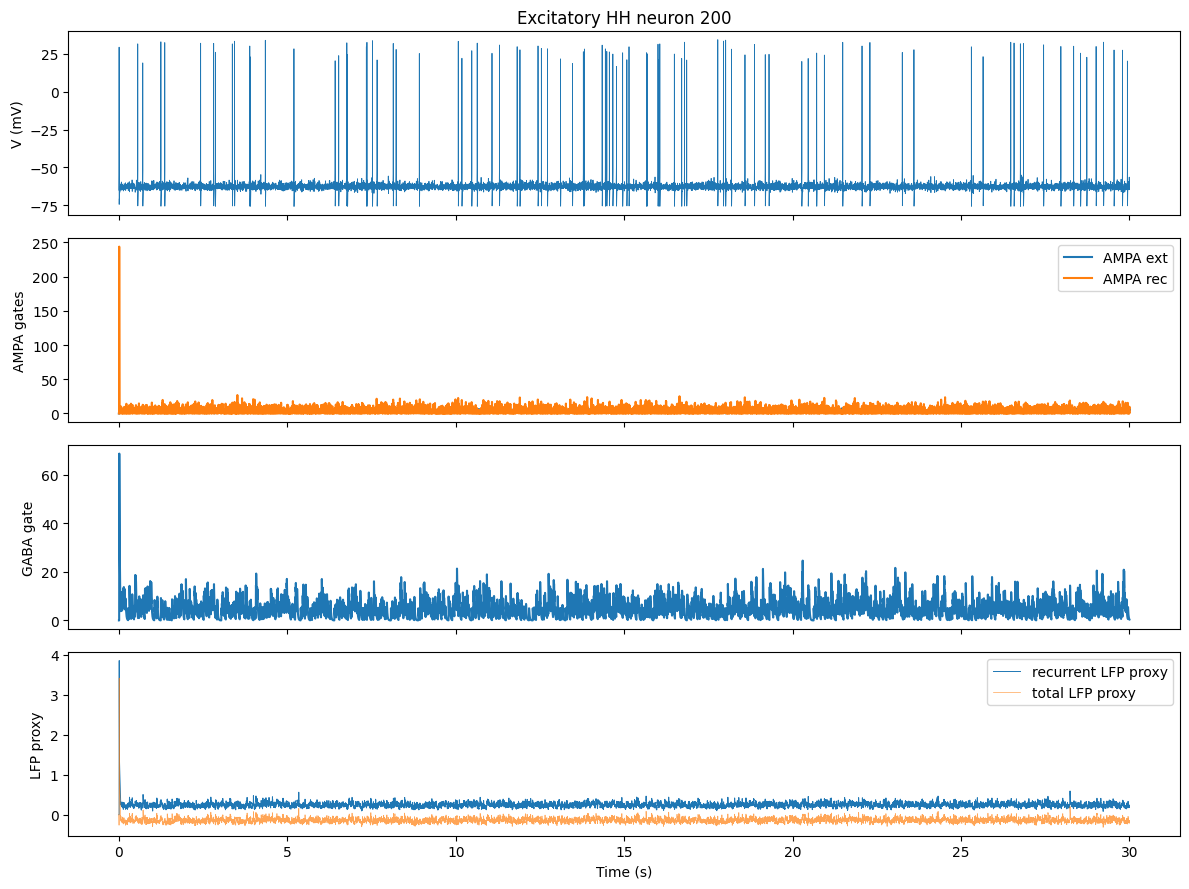

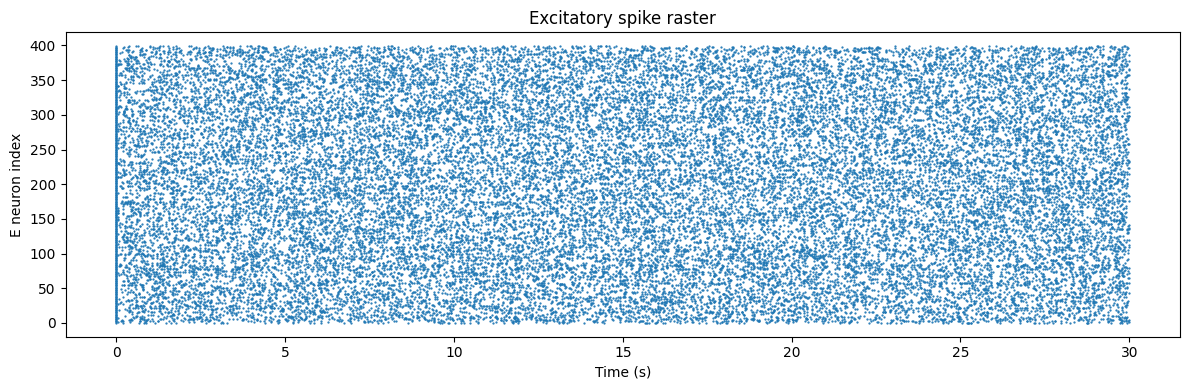

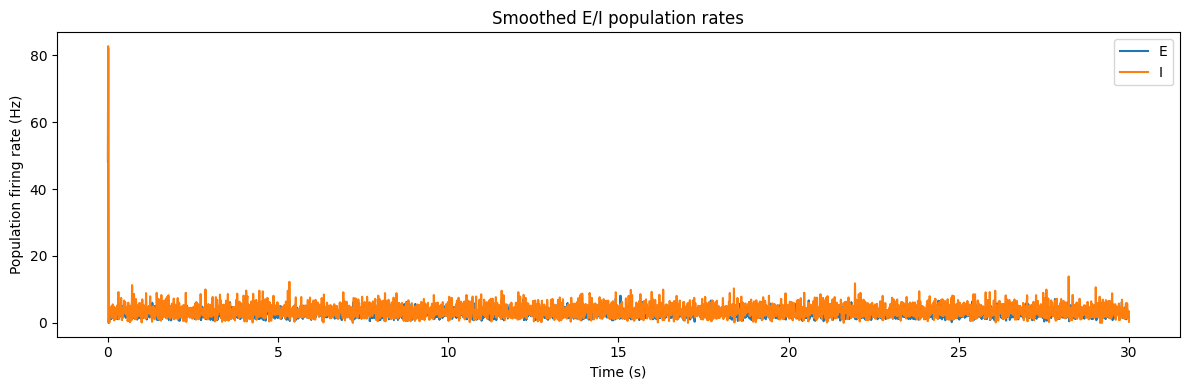

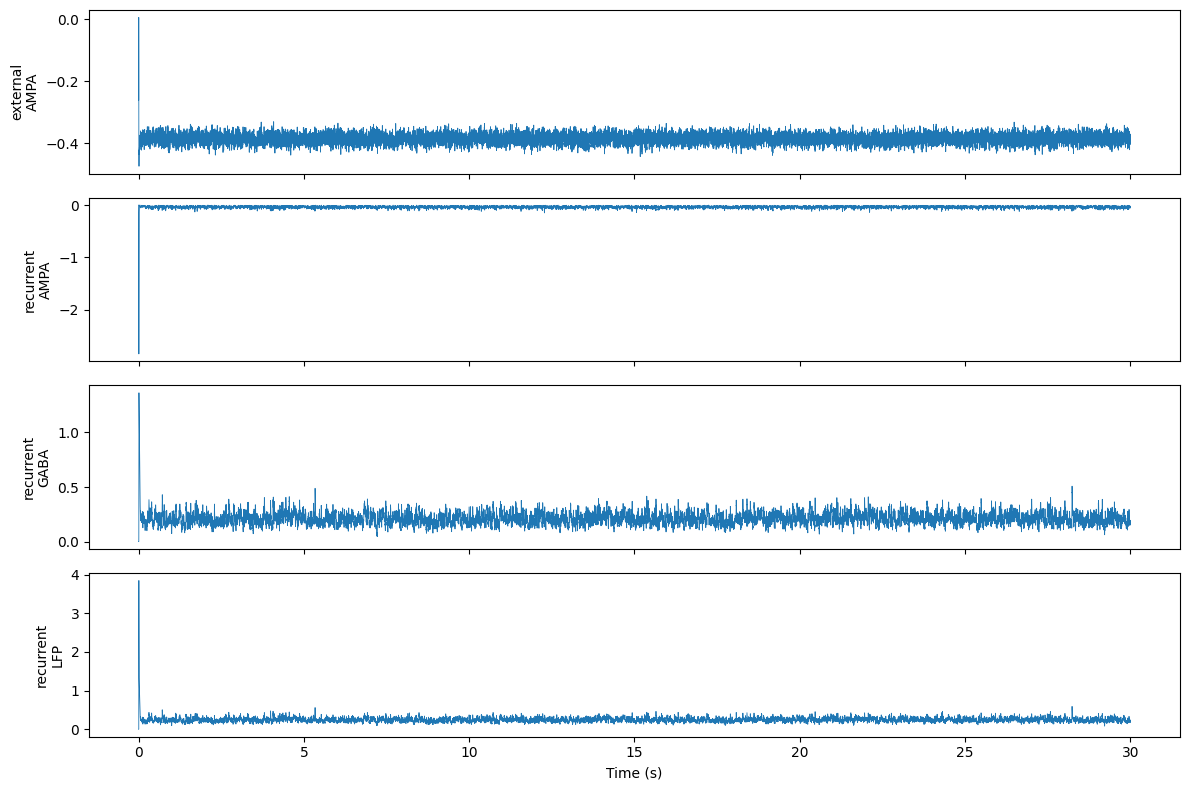

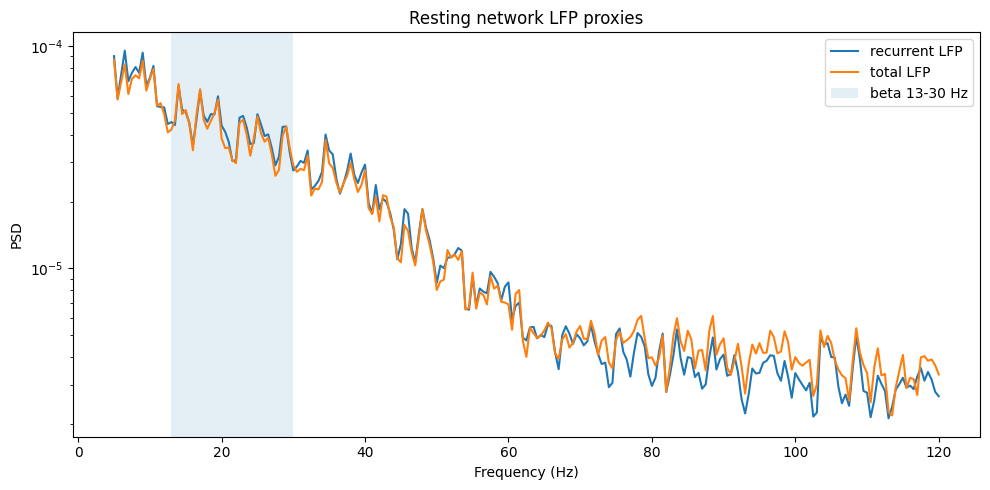

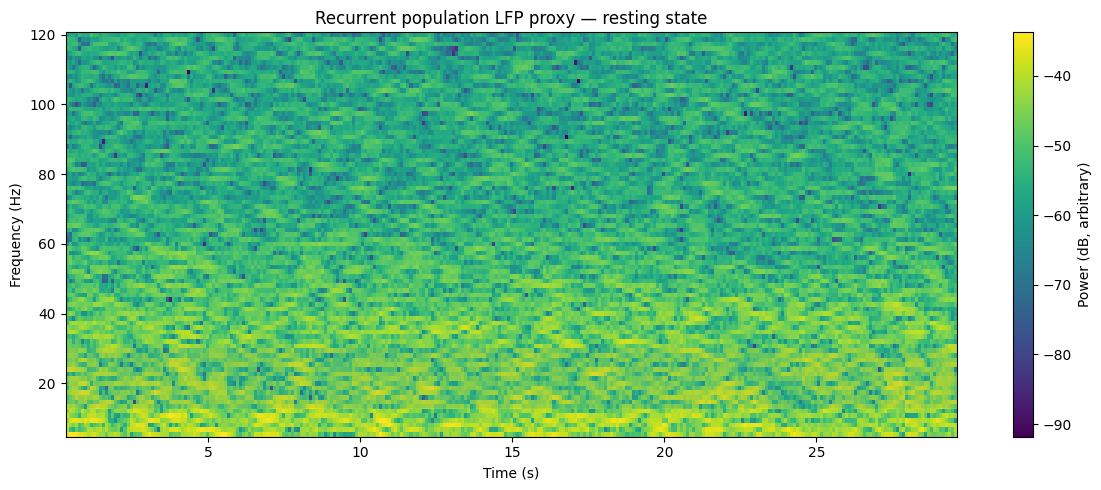

In [32]:
plot_resting_network(fmax=120)
